# Mask R-CNN - Train on JuniperMapper

This notebook shows how to train Mask R-CNN on [JuniperMapper dataset](https://zenodo.org/records/10058715).

In [1]:
from matplotlib import pyplot as plt
import os
import sys
import numpy as np

from keras.callbacks import CSVLogger

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'bin'))
import mrcnn.model as modellib
from mrcnn import utils # type: ignore
from mrcnn import visualize

from shrubs import ShrubConfig, ShrubDataset

Using TensorFlow backend.


## Configurations

In [2]:
%matplotlib inline 

ROOT = os.path.join(os.path.dirname(os.getcwd()))

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT, "data/logs")

# Directory with train data
TRAIN_DIR = os.path.join(
    ROOT,
    "data/JuniperMapper", "Photo_Interpretation_Data"
)

# Local path to store the COCO trained weights
COCO_MODEL_PATH = os.path.join(ROOT, "data/logs/mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

In [3]:
config = ShrubConfig()
config.display()


Configurations:
BACKBONE                       resnet101
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     8
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        100
DETECTION_MIN_CONFIDENCE       0.7
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 8
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  448
IMAGE_META_SIZE                14
IMAGE_MIN_DIM                  448
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              none
IMAGE_SHAPE                    [448 448   3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE               

Store the loss and other metrics produced during training phase into a CSV file.

In [4]:
csv_logger = CSVLogger(
    filename="training_metrics.csv",
    separator=",",
    append=True
)

## Notebook Preferences

In [5]:
def get_ax(rows=1, cols=1, size=8):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Change the default size attribute to control the size
    of rendered images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

## Dataset

In [6]:
# Training dataset
dataset_train = ShrubDataset()
dataset_train.load_dataset(
    os.path.join(TRAIN_DIR, "Train", "Images"),
    os.path.join(TRAIN_DIR, "Train", "masks_points.json")
)
dataset_train.prepare()

# Validation dataset
dataset_val = ShrubDataset()
dataset_val.load_dataset(
    os.path.join(TRAIN_DIR, "Test", "Images"),
    os.path.join(TRAIN_DIR, "Test", "masks_points.json")
)
dataset_val.prepare()

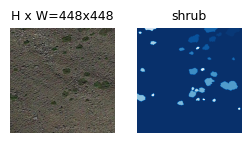

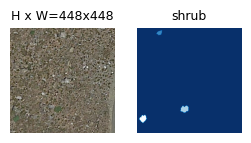

In [7]:
# Load and display random samples
image_ids = np.random.choice(dataset_train.image_ids, 2)
for image_id in image_ids:
    image = dataset_train.load_image(image_id)
    mask, class_ids = dataset_train.load_mask(image_id)
    visualize.display_top_masks(
        image,
        mask,
        class_ids,
        dataset_train.class_names,
        limit=1,
        figsize=(3,3)
    )

## Create Model

In [8]:
# Create model in training mode
model = modellib.MaskRCNN(
    mode="training",
    config=config,
    model_dir=MODEL_DIR
)

In [9]:
# Start with weights from COCO
# Also available: imagenet or last
init_with = "coco"

if init_with == "imagenet":
    model.load_weights(model.get_imagenet_weights(), by_name=True)
elif init_with == "coco":
    # Load weights trained on MS COCO, but skip layers that
    # are different due to the different number of classes
    # See README for instructions to download the COCO weights
    excluded_layers = [
        "mrcnn_class_logits",
        "mrcnn_bbox_fc", 
        "mrcnn_bbox",
        "mrcnn_mask"
    ]

    model.load_weights(COCO_MODEL_PATH, by_name=True, exclude=excluded_layers)

elif init_with == "last":
    # Load the last model you trained and continue training
    model.load_weights(model.find_last(), by_name=True)

## Training

Perform transfer learning to fine tunning only the heads. The backbone layers are freezing and training only the randomly initialized layers (i.e. the ones that we didn't use pre-trained weights from MS COCO). To train only the head layers, pass `layers='heads'` to the `train()` function.

In [10]:
print("Model directory:", model.model_dir)
print("Log directory:", model.log_dir)
print("Checkpoint path:", model.checkpoint_path)

Model directory: c:\IRANZO\shrubs-segmentation\data/logs
Log directory: c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg
Checkpoint path: c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg\mask_rcnn_shrubs_cfg_{epoch:04d}.h5


In [11]:
# Train the head branches
# Passing layers="heads" freezes all layers except the head
# layers. You can also pass a regular expression to select
# which layers to train by name pattern.
model.train(
    dataset_train,
    dataset_val, 
    learning_rate=config.LEARNING_RATE, 
    epochs=20, 
    layers='heads',
    custom_callbacks=[csv_logger]
)


Starting at epoch 0. LR=0.001

Checkpoint Path: c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg\mask_rcnn_shrubs_cfg_{epoch:04d}.h5
Selecting layers to train
fpn_c5p5               (Conv2D)
fpn_c4p4               (Conv2D)
fpn_c3p3               (Conv2D)
fpn_c2p2               (Conv2D)
fpn_p5                 (Conv2D)
fpn_p2                 (Conv2D)
fpn_p3                 (Conv2D)
fpn_p4                 (Conv2D)
In model:  rpn_model
    rpn_conv_shared        (Conv2D)
    rpn_class_raw          (Conv2D)
    rpn_bbox_pred          (Conv2D)
mrcnn_mask_conv1       (TimeDistributed)
mrcnn_mask_bn1         (TimeDistributed)
mrcnn_mask_conv2       (TimeDistributed)
mrcnn_mask_bn2         (TimeDistributed)
mrcnn_class_conv1      (TimeDistributed)
mrcnn_class_bn1        (TimeDistributed)
mrcnn_mask_conv3       (TimeDistributed)
mrcnn_mask_bn3         (TimeDistributed)
mrcnn_class_conv2      (TimeDistributed)
mrcnn_class_bn2        (TimeDistributed)
mrcnn_mask_conv4       (TimeDistributed)
mr

c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\tensorflow_core\python\framework\indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\tensorflow_core\python\framework\indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\tensorflow_core\python\framework\indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "


Epoch 1/20
100/100 [==============================] - 4802s 48s/step - loss: 1.9570 - val_loss: 1.2885
Epoch 2/20
100/100 [==============================] - 4735s 47s/step - loss: 1.5232 - val_loss: 1.6818
Epoch 3/20
100/100 [==============================] - 4722s 47s/step - loss: 1.3557 - val_loss: 1.0232
Epoch 4/20
100/100 [==============================] - 4727s 47s/step - loss: 1.2711 - val_loss: 1.2165
Epoch 5/20
100/100 [==============================] - 4718s 47s/step - loss: 1.2110 - val_loss: 1.1181
Epoch 6/20
100/100 [==============================] - 4712s 47s/step - loss: 1.1508 - val_loss: 1.6434
Epoch 7/20
100/100 [==============================] - 4653s 47s/step - loss: 1.1486 - val_loss: 1.0531
Epoch 8/20
100/100 [==============================] - 4664s 47s/step - loss: 1.0910 - val_loss: 0.9682
Epoch 9/20
100/100 [==============================] - 4685s 47s/step - loss: 1.0668 - val_loss: 1.1614
Epoch 10/20
100/100 [==============================] - 4691s 47s/step - l